# Applied AI - Machine Learning tutorial

Work through the notebook and answer the questions.

Run the cells from top to bottom. Each section uses its own variable names so that the Tips, Iris, and life expectancy data remain separate.

# Regression (prediction) : Linear Regression

In this task, you will be using a dataset that has recorded the tips given by restaurant customers.

## 1.- Load and explore the dataset

In [1]:
import seaborn as sns
tips = sns.load_dataset("tips")

In [2]:
from IPython.display import display

display(tips.head())
tips.info()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


Have a look at the data in the Tips dataset here:
https://github.com/mwaskom/seaborn-data/blob/master/tips.csv

**Question: How many variables does the dataset have? Which variables are numerical and which variables are categorical?**

**Answer:** There are **7 variables**.

- Numerical: `total_bill`, `tip`, and `size`.
- Categorical: `sex`, `smoker`, `day`, and `time`.

**Question: How many samples do you have in the dataset?**

Hint: you can use the .info or .count functions here.

**Answer:** There are **244 samples (rows)**. All seven columns have 244 non-null values, so there are no missing values.

## 2.- Visualise data from dataset

We will now plot two of the variables: total_bill and tip:

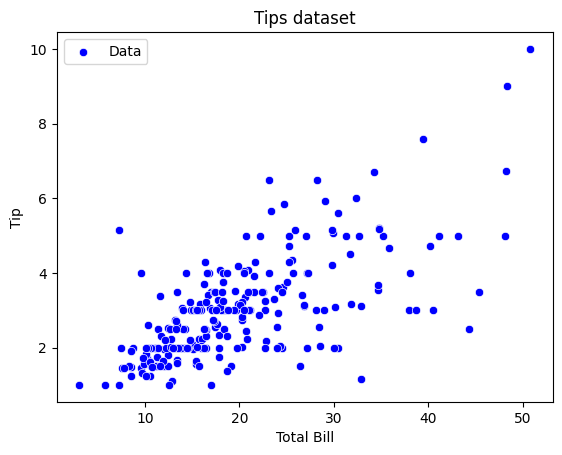

In [3]:
import matplotlib.pyplot as plt
sns.scatterplot(x="total_bill", y="tip", data=tips, color='blue', label='Data')
plt.xlabel('Total Bill')
plt.ylabel('Tip')
plt.legend()
plt.title('Tips dataset')
plt.show()

Each dot represents one bill and its tip. Larger bills generally receive larger tips, giving a positive relationship. The spread shows that similar bills can receive different tips.

## 3.- Problem: Given a total bill, predict the tip

First, we will get the data for total_bill and tip:

In [4]:
# Input: total bill. Target: tip amount.
tips_x = tips[["total_bill"]].values
tips_y = tips["tip"].values

It's very important that for evaluation we split our dataset into train and test:
We will use 80% of the data for training and 20% of the data for testing.

In [5]:
from sklearn.model_selection import train_test_split

# Leave the split random so we can explore how evaluation changes between runs.
tips_x_train, tips_x_test, tips_y_train, tips_y_test = train_test_split(
    tips_x, tips_y, test_size=0.2
)

**Question: How many samples (rows) do you have in the test set? How many samples do you have in the train set?**

Hint: you can use the .size function here.

In [6]:
print("Training samples:", len(tips_x_train))
print("Test samples:", len(tips_x_test))

Training samples: 195
Test samples: 49


**Answer:** There are **195 training samples** and **49 test samples**. The model learns from the training set and is evaluated on the held-out test set.

## 4.- Create a Regression model and plot results:

In [7]:
from sklearn.linear_model import LinearRegression

tips_model = LinearRegression()
tips_model.fit(tips_x_train, tips_y_train)

# Predict tips for the held-out test bills.
tips_predictions = tips_model.predict(tips_x_test)

## 5.- Visualisation (qualitative evaluation)

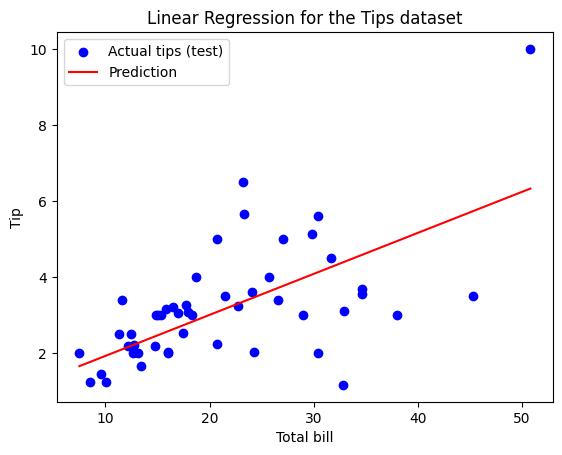

In [8]:
# Sort the bills so the regression line is drawn from left to right.
tips_order = tips_x_test[:, 0].argsort()

plt.scatter(tips_x_test[:, 0], tips_y_test, color='blue', label='Actual tips (test)')
plt.plot(
    tips_x_test[tips_order, 0], tips_predictions[tips_order],
    color='red', label='Prediction'
)
plt.xlabel('Total bill')
plt.ylabel('Tip')
plt.legend()
plt.title('Linear Regression for the Tips dataset')
plt.show()

The blue dots are the actual test tips. The red line shows the model's predictions. The vertical gap between a dot and the line is its prediction error.

## 6.- Quantitative evaluation

In [9]:
from sklearn.metrics import mean_squared_error, r2_score

tips_mse = mean_squared_error(tips_y_test, tips_predictions)
tips_r2 = r2_score(tips_y_test, tips_predictions)

print(f'Mean Squared Error: {tips_mse:.2f}')
print(f'R-squared (R2) Score: {tips_r2:.2f}')

Mean Squared Error: 1.55
R-squared (R2) Score: 0.34


**Interpretation:** MSE is the average squared prediction error; lower is better, and zero means perfect predictions. R-squared measures the proportion of variation in the test tips explained by the predictions. The scores can change because the split is random.

**Question: If you run the notebook again (from the beginning) do you get the same results in terms of Mean Squared Error (MSE)? Why?**

**Answer:** The MSE will usually change when the notebook is run again. `train_test_split()` randomly chooses the training and test samples, so the model learns from different data and is evaluated on different data each time. Setting `random_state=42` in the split would make it repeatable. This section intentionally leaves the split random to demonstrate that effect.

# Decision Trees

For the decision trees task, we will be working with the iris dataset (flowers).

## 1.- Load the dataset

In [10]:
from sklearn.datasets import load_iris

iris = load_iris()
iris_x, iris_y = iris.data, iris.target

## 2.- Explore the dataset

First, plot sepal length against sepal width.
In `iris_x`, column 0 is sepal length and column 1 is sepal width.

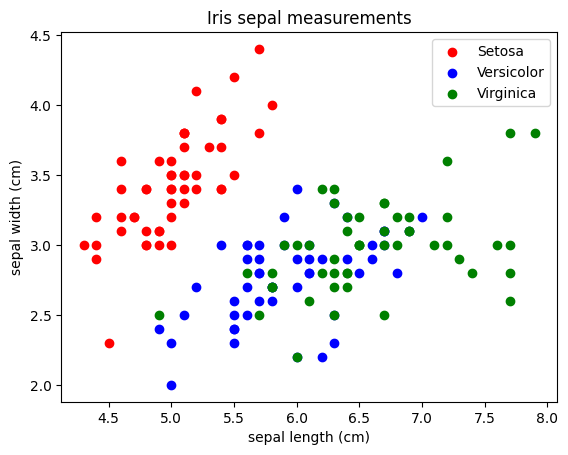

In [11]:
import matplotlib.pyplot as plt

plt.scatter(iris_x[iris_y == 0, 0], iris_x[iris_y == 0, 1], c='red', label='Setosa')
plt.scatter(iris_x[iris_y == 1, 0], iris_x[iris_y == 1, 1], c='blue', label='Versicolor')
plt.scatter(iris_x[iris_y == 2, 0], iris_x[iris_y == 2, 1], c='green', label='Virginica')
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.title('Iris sepal measurements')
plt.legend()
plt.show()

**Using the example above, plot the petal length and the petal width.**

Hint: Petal length is column 2 in `iris_x`, and petal width is column 3.

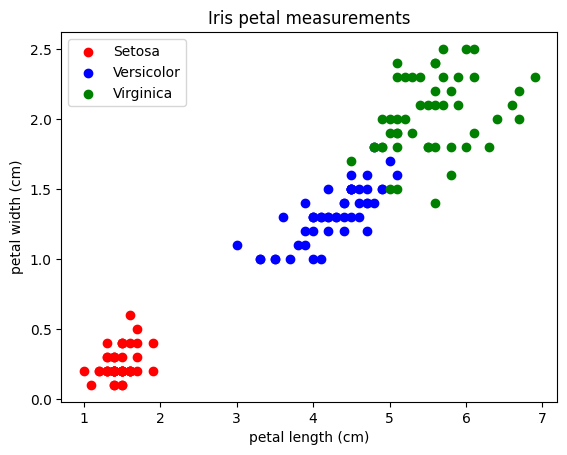

In [12]:
plt.scatter(iris_x[iris_y == 0, 2], iris_x[iris_y == 0, 3], c='red', label='Setosa')
plt.scatter(iris_x[iris_y == 1, 2], iris_x[iris_y == 1, 3], c='blue', label='Versicolor')
plt.scatter(iris_x[iris_y == 2, 2], iris_x[iris_y == 2, 3], c='green', label='Virginica')
plt.xlabel(iris.feature_names[2])
plt.ylabel(iris.feature_names[3])
plt.title("Iris petal measurements")
plt.legend()
plt.show()

**Observation:** Setosa is clearly separated using petal measurements. Versicolor and Virginica are also easier to distinguish than in the sepal plot, although some overlap remains.

## 3.- Problem: Classify the iris dataset

First, we will have to split the dataset into test and train sets.

In [13]:
from sklearn.model_selection import train_test_split

iris_x_train, iris_x_test, iris_y_train, iris_y_test = train_test_split(
    iris.data, iris.target, test_size=0.2
)

Print the number of samples (rows) in the training and test sets.

In [14]:
print("Training samples:", len(iris_x_train))
print("Test samples:", len(iris_x_test))

Training samples: 120
Test samples: 30


**Answer:** There are **120 training samples** and **30 test samples**.

## 4.- Create a Decision Tree model and plot results

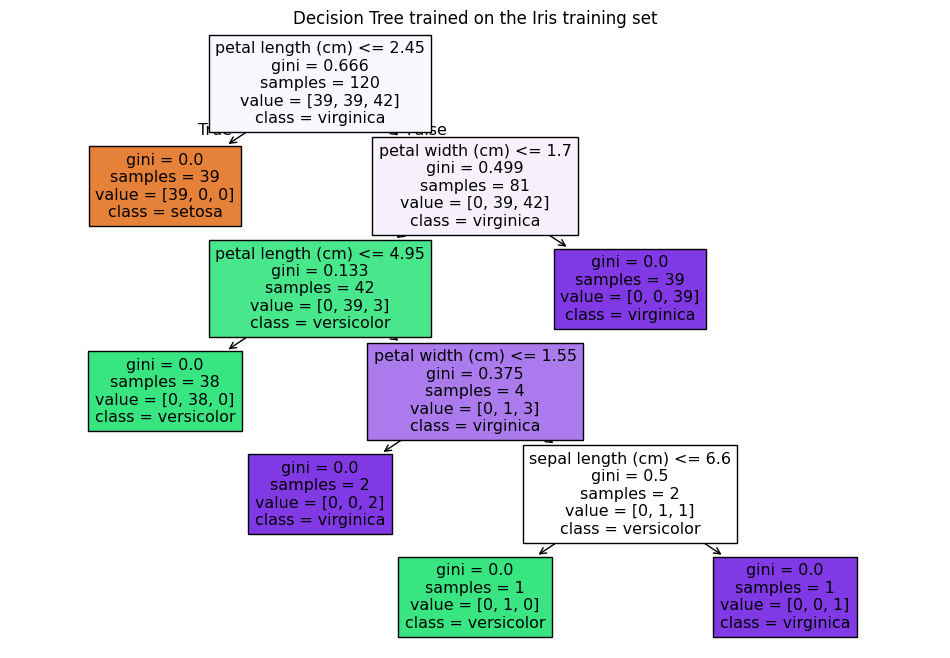

In [15]:
from sklearn import tree

decision_tree = tree.DecisionTreeClassifier()
decision_tree.fit(iris_x_train, iris_y_train)
iris_predictions = decision_tree.predict(iris_x_test)

plt.figure(figsize=(12, 8))
tree.plot_tree(
    decision_tree,
    feature_names=iris.feature_names,
    class_names=list(iris.target_names),
    filled=True
)
plt.title("Decision Tree trained on the Iris training set")
plt.show()

Start at the top of the tree and follow each measurement rule: true goes left and false goes right. Each leaf predicts a species. `samples` counts the training flowers reaching a node; `gini = 0` means they all have the same species. The tree is trained on 120 flowers, and the remaining 30 are reserved for testing.

## 5.- Quantitative evaluation

In [16]:
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score

iris_mse = mean_squared_error(iris_y_test, iris_predictions)
iris_r2 = r2_score(iris_y_test, iris_predictions)
iris_accuracy = accuracy_score(iris_y_test, iris_predictions)

print(f'Mean Squared Error: {iris_mse:.2f}')
print(f'R-squared (R2) Score: {iris_r2:.2f}')
print(f'Accuracy: {iris_accuracy:.2f}')
print(f'Correct predictions: {(iris_y_test == iris_predictions).sum()} / {len(iris_y_test)}')

Mean Squared Error: 0.07
R-squared (R2) Score: 0.89
Accuracy: 0.93
Correct predictions: 28 / 30


**Interpretation:** Accuracy is the proportion of test flowers classified correctly; multiply it by 100 to express it as a percentage. For example, 28 correct predictions out of 30 gives approximately 93% accuracy. The actual result above can vary with the random split. MSE and R-squared are retained from the tutorial, but accuracy is the appropriate main measure here because species codes are categories rather than numerical quantities.

**Question: Predict the class of a new sample with the following values: [6.3, 2.9, 5.5, 2.3] and print the class name**

Hints:

To predict you will have to call the predict function with the values inside a list: [[6.3, 2.9, 5.5, 2.3]]

To print the class name, you may need to use iris.target_names

In [17]:
new_sample = [[6.3, 2.9, 5.5, 2.3]]

prediction = decision_tree.predict(new_sample)
class_name = iris.target_names[prediction[0]]
print("Predicted species:", class_name)

Predicted species: virginica


The measurements are sepal length, sepal width, petal length, and petal width, in centimetres. The expected prediction for this sample is **Virginica**; the code above prints the model's actual result.

# Unsupervised learning: K-Means clustering

Use K-Means to group the Iris flowers by similar measurements, without using their species labels.

## 1.- Load the dataset

In [18]:
from sklearn.datasets import load_iris

# Load Iris dataset
iris = load_iris()

## 2.- Problem: Group the Iris dataset

This is an unsupervised approach, so we use the measurements without the species labels.
Fit K-Means to all 150 flowers; this exercise does not use a train/test split.
Print the number of samples and check that there are four measurements per flower.

In [19]:
cluster_x = iris.data

print("Samples:", len(cluster_x))
print("Data shape:", cluster_x.shape)

Samples: 150
Data shape: (150, 4)


## 3.- Create a K-Means model and plot results

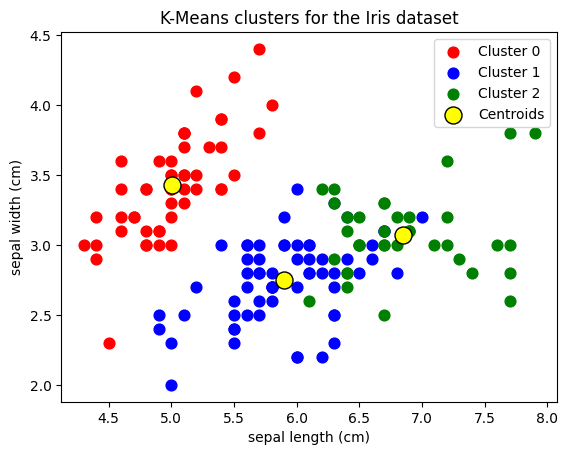

In [20]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

kmeans_model = KMeans(
    n_clusters=3, max_iter=300, n_init=10, init='random', random_state=42
)
cluster_labels = kmeans_model.fit_predict(cluster_x)

# Clustering uses all four measurements; this plot displays the first two.
plt.scatter(cluster_x[cluster_labels == 0, 0], cluster_x[cluster_labels == 0, 1],
            s=60, c='red', label='Cluster 0')
plt.scatter(cluster_x[cluster_labels == 1, 0], cluster_x[cluster_labels == 1, 1],
            s=60, c='blue', label='Cluster 1')
plt.scatter(cluster_x[cluster_labels == 2, 0], cluster_x[cluster_labels == 2, 1],
            s=60, c='green', label='Cluster 2')
plt.scatter(kmeans_model.cluster_centers_[:, 0], kmeans_model.cluster_centers_[:, 1],
            s=150, c='yellow', edgecolors='black', label='Centroids')
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.title('K-Means clusters for the Iris dataset')
plt.legend()
plt.show()

The coloured dots show the assigned clusters, and the yellow dots show their centres (centroids). Cluster numbers do not automatically correspond to species names. The model uses all four measurements, although this plot displays only sepal length and width.

## 4.- Evaluation

In [21]:
inertia = kmeans_model.inertia_
print(f'Inertia: {inertia:.2f}')

Inertia: 78.85


**Interpretation:** Inertia is the sum, across all 150 flowers, of the squared distance from each flower to its assigned centroid. Each distance uses all four measurements. Lower inertia means tighter clusters, but increasing the number of clusters usually reduces it too; use the Elbow method to compare different K values.

## The Elbow method

**Task: Implement the Elbow method**

Compare the inertia for different numbers of clusters. More clusters usually reduce inertia, so a low inertia alone does not identify a suitable number of clusters.

Use a for loop to fit K-Means with 1 through 10 clusters, and plot the inertia for each K.
Look for the bend where the decrease in inertia starts to slow. For this dataset, K = 3 is a reasonable choice. The elbow is a visual guide rather than proof of a unique optimal K.

The Iris species labels are available in the dataset, but they are not used to fit K-Means.

Data shape: (150, 4)


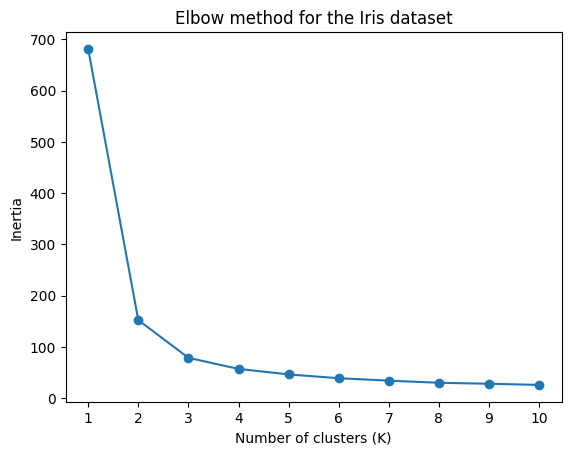

In [22]:
# Explicitly select the Iris measurements to avoid using another dataset.
cluster_x = load_iris().data
print("Data shape:", cluster_x.shape)  # (150, 4)

inertias = []
for k in range(1, 11):
    candidate = KMeans(n_clusters=k, n_init=10, random_state=42)
    candidate.fit(cluster_x)
    inertias.append(candidate.inertia_)

plt.plot(range(1, 11), inertias, marker='o')
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow method for the Iris dataset")
plt.xticks(range(1, 11))
plt.show()

**Answer:** **K = 3** is a reasonable choice: inertia falls sharply over the first few K values, then the improvements become smaller. The elbow is around three clusters. The curve uses the 150 Iris flowers with all four measurements.

# Additional Task

Use the life expectancy dataset to predict the life expectancy.
Choose one of the models above.

You will find the dataset here:

https://github.com/mwaskom/seaborn-data/blob/master/healthexp.csv

## 1.- Load and explore the life expectancy dataset

Use **Linear Regression** to predict `Life_Expectancy` from `Spending_USD`. The target is numerical, so this is a regression problem.

In [23]:
import seaborn as sns

health = sns.load_dataset("healthexp")
display(health.head())
health.info()

,Year,Country,Spending_USD,Life_Expectancy
0,1970,Germany,252.311,70.6
1,1970,France,192.143,72.2
2,1970,Great Britain,123.993,71.9
3,1970,Japan,150.437,72.0
4,1970,USA,326.961,70.9


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 274 entries, 0 to 273
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             274 non-null    int64  
 1   Country          274 non-null    object 
 2   Spending_USD     274 non-null    float64
 3   Life_Expectancy  274 non-null    float64
dtypes: float64(2), int64(1), object(1)
memory usage: 8.7+ KB


The dataset contains **274 rows and 4 columns**, with no missing values. `Country` is categorical; `Year`, `Spending_USD`, and `Life_Expectancy` are numerical. This exercise uses healthcare spending as the single input.

## 2.- Select the variables and split the data

Use 80% of the data for training and 20% for testing. A fixed random state makes this split repeatable.

In [24]:
from sklearn.model_selection import train_test_split

health_x = health[["Spending_USD"]]
health_y = health["Life_Expectancy"]

health_x_train, health_x_test, health_y_train, health_y_test = train_test_split(
    health_x, health_y, test_size=0.2, random_state=42
)

print("Training samples:", len(health_x_train))
print("Test samples:", len(health_x_test))

Training samples: 219
Test samples: 55


There are **219 training samples** and **55 test samples**.

## 3.- Train the Linear Regression model and make predictions

In [25]:
from sklearn.linear_model import LinearRegression

health_model = LinearRegression()
health_model.fit(health_x_train, health_y_train)
health_predictions = health_model.predict(health_x_test)

## 4.- Evaluate the predictions

In [26]:
from sklearn.metrics import mean_squared_error, r2_score

health_mse = mean_squared_error(health_y_test, health_predictions)
health_r2 = r2_score(health_y_test, health_predictions)
health_rmse = health_mse ** 0.5

print(f"Mean Squared Error: {health_mse:.2f}")
print(f"R2 Score: {health_r2:.2f}")
print(f"Root Mean Squared Error (years): {health_rmse:.2f}")

Mean Squared Error: 7.85
R2 Score: 0.36
Root Mean Squared Error (years): 2.80


## 5.- Visualise the actual values and predictions

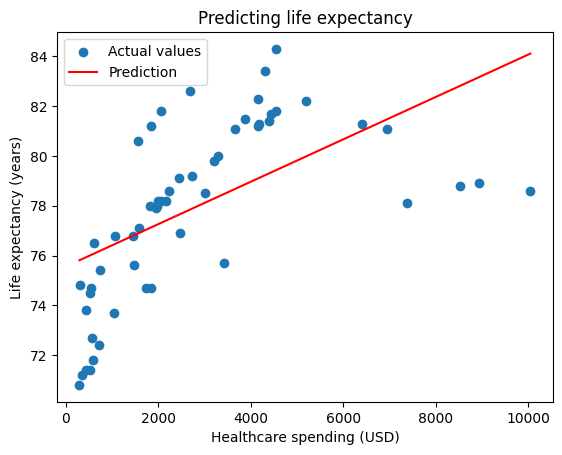

In [27]:
import matplotlib.pyplot as plt

sorted_x = health_x_test.sort_values("Spending_USD")

plt.scatter(
    health_x_test["Spending_USD"], health_y_test,
    label="Actual values"
)
plt.plot(
    sorted_x["Spending_USD"], health_model.predict(sorted_x),
    color="red", label="Prediction"
)
plt.xlabel("Healthcare spending (USD)")
plt.ylabel("Life expectancy (years)")
plt.title("Predicting life expectancy")
plt.legend()
plt.show()

## Conclusion

Linear Regression was used to predict life expectancy from healthcare spending. The model achieved a test **MSE of 7.85 years squared**, an **RMSE of approximately 2.80 years**, and an **R-squared of 0.36**. On this test split, spending alone explains about 36% of the variation in life expectancy, leaving substantial variation unexplained.

The blue dots show the actual test values and the red line shows the predictions. Their vertical gaps are prediction errors. This is a simple model based on one input; the relationship does not establish that increased spending causes increased life expectancy.